# 01 Kollmeyer data cleaning (v2)

Cleans every CSV of the raw Kollmeyer LG 18650HG2 data (drive D, read only) into an independent time series with the columns `time_s, voltage, current, temperature, soc, ah`. No windowing, no normalisation, no train/test split.

- Code: `src/preprocess_kollmeyer.py` (every manual decision is a constant at the top of the file)
- Output: `data/processed/kollmeyer_clean/` (temperature subfolders, `_excluded/`, `manifest.json`, `file_timeline.csv`)
- Every processing decision and its reason: `data/processed/kollmeyer_clean/DATA_REPORT.md`

Running cell 2 below regenerates all outputs from the raw data (about 1-2 minutes); `DATA_REPORT.md` is not changed.

Note (2026-10-03): the text of this notebook, of its recorded outputs and of the generated manifest / timeline was translated to English; the numbers are unchanged. The figure output of section 5 was removed because its labels were in Chinese; rerun that cell to redraw it with English labels (needs the raw data).

In [1]:
import os, sys, importlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, 'src'))
import preprocess_kollmeyer as pk
importlib.reload(pk)
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 80); pd.set_option('display.max_rows', 120)
print('raw data :', pk.RAW_ROOT)
print('output   :', pk.OUT_DIR)

raw data : D:\kdata\LG 18650HG2 Li-ion Battery Data and Example Deep Neural Network xEV SOC Estimator Script\LG_HG2_Original_Dataset_McMasterUniversity_Jan_2020
output   : C:\Users\chiay\Desktop\battery-fyp\data\processed\kollmeyer_clean


In [2]:
result = pk.run()
T = pk.tables(result)

Raw CSV files: 208


Aging rate: pooled 0.0652 %/Ah, -20 degC 0.2592 %/Ah


Series written: main data set 102, _excluded 129


## 1. Full capacity of every batch

Rule 1: the batch's own Cap_1C (right temperature); rule 2: back-calculated from the cutoff capacity, within 0.5 % of the aging-model prediction; rule 3: the nearest valid capacity at the same temperature + aging correction. 567 failed rule 2 and uses the rule-3 approach; 556 has no same-temperature reference and only a cross-temperature check. Characterisation files are aging-corrected one by one according to their start time.

In [3]:
cols = ['folder', 'batch', 'file', 'rule', 'capacity_Ah', 'before_correction_Ah', 'delta_Ah', 'end_soc_min', 'end_soc_max', 'source']
T['capacities'][cols].round(5)

,folder,batch,file,rule,capacity_Ah,before_correction_Ah,delta_Ah,end_soc_min,end_soc_max,source
0,n20degC,607,607_HPPC,characterisation test (borrowed + aging correction),1.70709,1.67134,-8.07867,NaN,NaN,"borrowed 1.6713 Ah of 610, aging correction for 8.1 Ah (rate 0.2592 %/Ah, from the 610/611 pair only)"
1,n20degC,607,607_C20DisCh,characterisation test (borrowed + aging correction),1.69638,1.67134,-5.69530,NaN,NaN,"borrowed 1.6713 Ah of 610, aging correction for 5.7 Ah (rate 0.2592 %/Ah, from the 610/611 pair only)"
2,n20degC,607,607_Dis_0p5C,characterisation test (borrowed + aging correction),1.68533,1.67134,-3.20301,NaN,NaN,"borrowed 1.6713 Ah of 610, aging correction for 3.2 Ah (rate 0.2592 %/Ah, from the 610/611 pair only)"
3,n20degC,607,607_Dis_2C,characterisation test (borrowed + aging correction),1.67664,1.67134,-1.21991,NaN,NaN,"borrowed 1.6713 Ah of 610, aging correction for 1.2 Ah (rate 0.2592 %/Ah, from the 610/611 pair only)"
4,n20degC,610,NaN,1,1.67134,NaN,NaN,0.04993,0.04999,610_Cap_1C (measured in this batch)
5,n20degC,611,NaN,1,1.61717,NaN,NaN,0.04993,0.05000,611_Cap_1C (measured in this batch)
6,n10degC,593,593_HPPC,characterisation test (borrowed + aging correction),2.27735,2.26338,-9.40261,NaN,NaN,"borrowed 2.2634 Ah of 596, aging correction for 9.4 Ah (rate 0.0652 %/Ah)"
7,n10degC,593,593_C20DisCh,characterisation test (borrowed + aging correction),2.27341,2.26338,-6.76144,NaN,NaN,"borrowed 2.2634 Ah of 596, aging correction for 6.8 Ah (rate 0.0652 %/Ah)"
8,n10degC,593,593_Dis_0p5C,characterisation test (borrowed + aging correction),2.26960,2.26338,-4.20031,NaN,NaN,"borrowed 2.2634 Ah of 596, aging correction for 4.2 Ah (rate 0.0652 %/Ah)"
9,n10degC,593,593_Dis_2C,characterisation test (borrowed + aging correction),2.26612,2.26338,-1.85396,NaN,NaN,"borrowed 2.2634 Ah of 596, aging correction for 1.9 Ah (rate 0.0652 %/Ah)"


In [4]:
print('Aging model:', {k: v for k, v in result['aging'].items()})
T['rule2_checks'].round(5)

Aging model: {'rate_pooled_per_Ah': 0.0006524898934590464, 'pair_rates_per_Ah': {'551->552': 0.0006148061120997384, '596->602': 0.0006899508832341223}, 'rate_n20degC_per_Ah': 0.002592225927898649, 'n20degC_note': 'the -20 degC rate comes only from the pair 610 -> 611'}


,batch,folder,backcalc_Ah,reference,cross_temperature_estimate,cross_temperature_c25,passed,cross_check_ok,delta_Ah,predicted_Ah,deviation,deviation_range
0,556,40degC,2.65846,NaN,"(2.6472121028679334, 2.6603823123349386)",2.63404,None,True,NaN,NaN,NaN,NaN
1,567,10degC,2.61008,576,NaN,NaN,False,NaN,-50.43471,2.63319,-0.00878,"(-0.010712623230220153, -0.006828148404872669)"
2,582,10degC,2.54214,576,NaN,NaN,True,NaN,8.72075,2.53205,0.00398,"(0.0036520765644885156, 0.004313769937340561)"
3,590,0degC,2.45012,589,NaN,NaN,True,NaN,19.76045,2.44148,0.00354,"(0.002780796372522598, 0.004290401619843731)"
4,601,n10degC,2.24194,602,NaN,NaN,True,NaN,-9.83367,2.24631,-0.00195,"(-0.0023182657463094447, -0.001575993815665644)"
5,604,n10degC,2.21958,602,NaN,NaN,True,NaN,7.36383,2.22118,-0.00072,"(-0.0009976210669904173, -0.0004419968344090419)"


## 2. Included and excluded files

In [5]:
T['inclusion']

status,excluded,included,included (first attempt -> _excluded),included (tail -> _excluded)
test_type,,,,
C20DisCh,0,6,0,0
Cap_1C,2,8,0,0
Dis_0p5C,0,1,0,5
Dis_2C,0,1,0,5
HPPC,0,1,0,5
PausCycl,2,4,0,0
charge,98,0,0,0
drive,1,22,1,0
mixed,5,41,0,0


In [6]:
T['excluded_files'][T['excluded_files'].exclusion_class != '-']

,folder,name,exclusion_class,exclusion_reason
111,10degC,571_Cap_1C,a,actually discharged at about 0.7-3.6 degC (the chamber was cold only in this step); not 10 degC data
151,25degC,551_HWFET,b,"the HWFET profile was not executed: the current is 0 throughout, the file only holds a 10-minute rest"
172,25degC,552_PausCycl,b,the cycle was not executed: all 4 TABLE steps ended at once; only rests and one 0.015 Ah top-up charge
191,40degC,557_Cap_1C,b,during the discharge the cell cooled from 38.4 degC to 1.3 degC; not at any constant temperature
202,40degC,562_Mixed4,b,"test chamber not switched on, the cell was at room temperature of about 23-25 degC; the program restarted at Charge10 and skipped Cap_1C, the cutoff capacity is only about 0.2 Ah; only 0.19 Ah discharged"
203,40degC,562_Mixed5,b,"test chamber not switched on, the cell was at room temperature of about 23-25 degC; the program restarted at Charge10 and skipped Cap_1C, the cutoff capacity is only about 0.2 Ah; only 0.19 Ah discharged"
204,40degC,562_Mixed6,b,"test chamber not switched on, the cell was at room temperature of about 23-25 degC; the program restarted at Charge10 and skipped Cap_1C, the cutoff capacity is only about 0.2 Ah; only 0.19 Ah discharged"
205,40degC,562_Mixed7,b,"test chamber not switched on, the cell was at room temperature of about 23-25 degC; the program restarted at Charge10 and skipped Cap_1C, the cutoff capacity is only about 0.2 Ah; only 0.19 Ah discharged"
206,40degC,562_Mixed8,b,"test chamber not switched on, the cell was at room temperature of about 23-25 degC; the program restarted at Charge10 and skipped Cap_1C, the cutoff capacity is only about 0.2 Ah; only 0.19 Ah discharged"
207,40degC,562_PausCycl,b,"test chamber not switched on, the cell was at room temperature of about 23-25 degC; the program restarted at Charge10 and skipped Cap_1C, the cutoff capacity is only about 0.2 Ah; ran for only 192 s"


## 3. Split positions (ProgTime or UTC time-stamp step larger than "logging interval + 3 s")

In [7]:
T['splits']

,series_block,split_before_raw_row,dt_progtime_s,dt_timestamp_s,reason
0,n10degC/602_Mixed4.csv / main,8027,415.993,416.0,logging gap 416.0 s
1,10degC/571_Mixed6.csv / main,391,0.003,37526.0,"hidden pause (ProgTime continuous, time stamp jumps 10.4 h)"
2,10degC/582_LA92.csv / attempt1,1943,16.202,16.0,logging gap 16.2 s
3,10degC/582_LA92.csv / attempt1,426,3.597,4.0,logging gap 3.6 s
4,25degC/549_Charge.csv / main,215,80262.652,80266.0,logging gap 80262.7 s
5,25degC/549_Charge.csv / main,431,151846.304,151846.0,logging gap 151846.3 s
6,25degC/549_Charge.csv / main,644,1668.849,1669.0,logging gap 1668.8 s


## 4. Temperature check (minimum temperature of the test part within 3 °C of the folder temperature)

In [8]:
S = T['series']
chk = S.assign(check=S.temperature.map(lambda x: x['check']))
print(chk.groupby(['excluded', 'check']).size())
chk[chk.check == 'fail'][['id', 'exclusion_reason']]

excluded  check                                
False     pass                                     102
True      fail                                       8
          n/a (charged at 22-25 degC by design)    116
          pass                                       5
dtype: int64


,id,exclusion_reason
121,_excluded/10degC/571_Cap_1C,actually discharged at about 0.7-3.6 degC (the chamber was cold only in this step); not 10 degC data
214,_excluded/40degC/557_Cap_1C,during the discharge the cell cooled from 38.4 degC to 1.3 degC; not at any constant temperature
225,_excluded/40degC/562_Mixed4,"test chamber not switched on, the cell was at room temperature of about 23-25 degC; the program restarted at Charge10 and skipped Cap_1C, the cutoff capacity is only about 0.2 Ah; only 0.19 Ah discharged"
226,_excluded/40degC/562_Mixed5,"test chamber not switched on, the cell was at room temperature of about 23-25 degC; the program restarted at Charge10 and skipped Cap_1C, the cutoff capacity is only about 0.2 Ah; only 0.19 Ah discharged"
227,_excluded/40degC/562_Mixed6,"test chamber not switched on, the cell was at room temperature of about 23-25 degC; the program restarted at Charge10 and skipped Cap_1C, the cutoff capacity is only about 0.2 Ah; only 0.19 Ah discharged"
228,_excluded/40degC/562_Mixed7,"test chamber not switched on, the cell was at room temperature of about 23-25 degC; the program restarted at Charge10 and skipped Cap_1C, the cutoff capacity is only about 0.2 Ah; only 0.19 Ah discharged"
229,_excluded/40degC/562_Mixed8,"test chamber not switched on, the cell was at room temperature of about 23-25 degC; the program restarted at Charge10 and skipped Cap_1C, the cutoff capacity is only about 0.2 Ah; only 0.19 Ah discharged"
230,_excluded/40degC/562_PausCycl,"test chamber not switched on, the cell was at room temperature of about 23-25 degC; the program restarted at Charge10 and skipped Cap_1C, the cutoff capacity is only about 0.2 Ah; ran for only 192 s"


## 5. Check figure

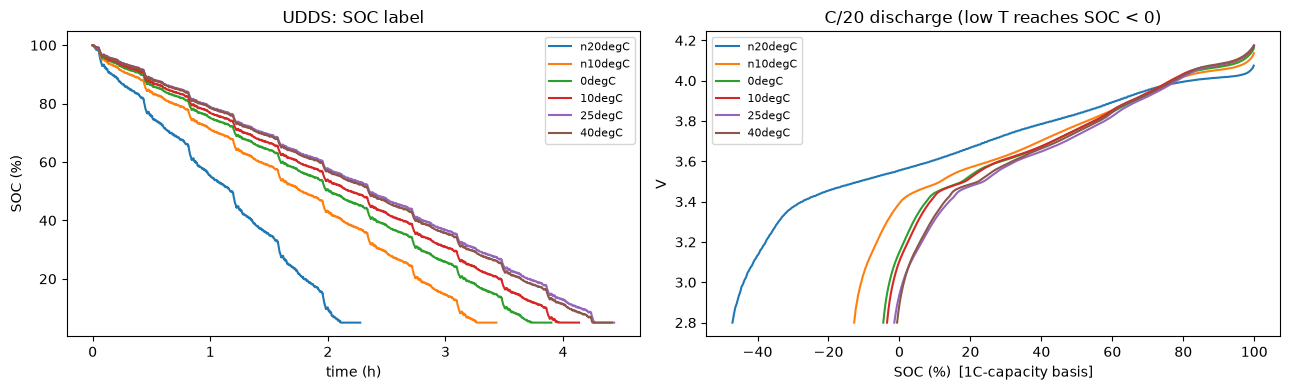

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for folder, batch in [('n20degC', '610'), ('n10degC', '596'), ('0degC', '589'), ('10degC', '576'), ('25degC', '551'), ('40degC', '556')]:
    d = pd.read_csv(os.path.join(pk.OUT_DIR, folder, f'{batch}_UDDS.csv'))
    ax[0].plot(d.time_s / 3600, d.soc * 100, label=folder)
ax[0].set_xlabel('time (h)'); ax[0].set_ylabel('SOC (%)'); ax[0].set_title('UDDS: SOC label'); ax[0].legend(fontsize=8)
for folder, batch in [('n20degC', '607'), ('n10degC', '593'), ('0degC', '585'), ('10degC', '575'), ('25degC', '549'), ('40degC', '555')]:
    d = pd.read_csv(os.path.join(pk.OUT_DIR, folder, f'{batch}_C20DisCh.csv'))
    dis = d[d.current < 0]
    ax[1].plot(dis.soc * 100, dis.voltage, label=folder)
ax[1].set_xlabel('SOC (%)  [1C-capacity basis]'); ax[1].set_ylabel('V'); ax[1].set_title('C/20 discharge (low T reaches SOC < 0)')
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

In [10]:
ev = result['events'].set_index('id')
caps = result['capacities']
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = {'n20degC': '#1f4e9c', 'n10degC': '#3a86c8', '0degC': '#56b4e9', '10degC': '#d62728', '25degC': '#2ca02c', '40degC': '#e69f00'}
for b, c in caps.items():
    key = f'{b}_Cap_1C' if f'{b}_Cap_1C' in ev.index else f'{b}_Cap_1C (missing)'
    filled = c['rule'] == '1'
    ax.scatter(ev.loc[key, 'cum_before_Ah'], c['capacity_Ah'], s=45, color=colors[c['folder']],
               facecolors=colors[c['folder']] if filled else 'none', zorder=3)
    ax.annotate(f"{b} ({c['rule'][0]})", (ev.loc[key, 'cum_before_Ah'], c['capacity_Ah']), fontsize=7, xytext=(3, 3), textcoords='offset points')
chk567 = T['rule2_checks'].set_index('batch').loc['567']
ax.scatter(ev.loc['567_Cap_1C (missing)', 'cum_before_Ah'], chk567.backcalc_Ah, marker='x', color=colors['10degC'], label='567 cutoff capacity 2.6101 (failed rule 2)')
for f, c in colors.items(): ax.scatter([], [], color=c, label=f)
ax.set_xlabel('Cumulative discharge (Ah, since 10/25)'); ax.set_ylabel('1C full capacity (Ah)')
ax.set_title('Full capacity per batch: filled = rule 1 measured, open = rule 2/3 or corrected')
ax.legend(fontsize=7); plt.tight_layout(); plt.show()

## 6. Read-back check

In [11]:
bad = []
for s in result['manifest']['series']:
    d = pd.read_csv(os.path.join(pk.OUT_DIR, s['file']))
    ok = (list(d.columns) == ['time_s', 'voltage', 'current', 'temperature', 'soc', 'ah'] and len(d) == s['rows']
          and d.time_s.iloc[0] == 0 and (len(d) < 2 or (np.diff(d.time_s.values) > 0).all())
          and not d[['time_s', 'voltage', 'current', 'temperature', 'ah']].isna().any().any()
          and (s['excluded'] or not d.soc.isna().any()))
    if not ok: bad.append(s['id'])
print('CSV files:', len(result['manifest']['series']), ' with problems:', bad)
pd.read_csv(os.path.join(pk.OUT_DIR, '10degC', '571_Mixed6_part2.csv')).head()

CSV files: 231  with problems: []


,time_s,voltage,current,temperature,soc,ah
0,0.000,4.16574,0.00000,9.14879,0.996116,-0.01008
1,0.042,4.16574,0.00000,9.14879,0.996116,-0.01008
2,0.145,4.18697,1.23108,9.14879,0.996131,-0.01004
3,0.241,4.19591,0.93481,9.14879,0.996143,-0.01001
4,0.342,4.19877,0.76879,9.14879,0.996151,-0.00999
